<img src="https://raw.githubusercontent.com/Nextia-Intelligence/nextia-learning-labs/main/nextia-notebook-branding/assets/courses/c25-header.png" alt="Nextia Learning · MLOps and LLMOps: Operating AI in Production" width="100%">

# Solution: Monitor a model on public data that changes

**[Monitor a model on public data that changes](https://learning.nextia-ai.com/courses/mlops/m07/monitor-a-model-on-public-data-that-changes/)** · MLOps and LLMOps: Operating AI in Production · Module 7, case study 1 of 2 · [learning.nextia-ai.com](https://learning.nextia-ai.com)

**You will** train a small model on real New York City 311 service requests from early 2020, then monitor it month by month while the city changes around it: lockdown, summer noise, fireworks, a tropical storm, new kinds of complaint. You measure input drift with the course's method, wait for labels that arrive late, measure the real accuracy, and find out when the drift mattered and when it did not.

| | |
|---|---|
| **Time** | About 2 hours with the case-study page. The notebook runs in about 1 minute. |
| **Needs** | An internet connection for the setup cells. No account, no key, no money: the model trains on your CPU in seconds. |
| **You should know** | The whole course, most of all [Data and concept drift](https://learning.nextia-ai.com/courses/mlops/m04/data-and-concept-drift/), [Delayed labels](https://learning.nextia-ai.com/courses/mlops/m04/delayed-labels/), [Service objectives](https://learning.nextia-ai.com/courses/mlops/m01/service-objectives/) and [Retrain or revise](https://learning.nextia-ai.com/courses/mlops/m05/retrain-or-revise/). |
| **Data** | NYC 311 Service Requests (NYC Open Data, `erm2-nwe9`): a fixed 1-in-20 sample of January 2020 to January 2021, 7 columns, no addresses. Published under the NYC Open Data Law: no licence requirement and no restrictions on use. |
| **Tested** | Python 3.12.13 with pandas 3.0.6, scikit-learn 1.9.1, numpy 2.5.3 and matplotlib 3.11.2, in Jupyter on macOS (Apple silicon), from a fresh start (*Restart and run all*) |

### How to use this notebook

This notebook has every query, task and check of the lesson. The [lesson page](https://learning.nextia-ai.com/courses/mlops/m07/monitor-a-model-on-public-data-that-changes/) has the full explanations, the diagrams and the knowledge checks that count toward your certificate. Keep both open.

1. Run the cells in order, from the top. Press **Shift+Enter** to run a cell and move to the next one.
2. At a **Predict** note, write your prediction down before you run the cell.
3. At a **Your turn** note, write your answer in the cell, run it, then run the check cell below it.
4. If you are stuck, open the [solution notebook](https://github.com/Nextia-Intelligence/nextia-learning-labs/blob/main/C25/monitor-311/monitor-311-solution.ipynb).

## Setup: install the packages

Run the next cell. It installs pandas 3.0.6 and scikit-learn 1.9.1, the versions that the course uses, and matplotlib 3.11.2 for the charts. It needs an internet connection and takes up to a minute the first time.

You should see `pandas 3.0.6` and `scikit-learn 1.9.1`. If you see other versions, restart the kernel (in Colab: **Runtime › Restart session**; in Kaggle: **Run › Restart & clear cell outputs**), then run this cell again.

In [1]:
%pip install -q --disable-pip-version-check pandas==3.0.6 scikit-learn==1.9.1 matplotlib==3.11.2
import pandas; print("pandas", pandas.__version__)
import sklearn; print("scikit-learn", sklearn.__version__)

Note: you may need to restart the kernel to use updated packages.


pandas 3.0.6


scikit-learn 1.9.1


## Setup: get the data

Run the next cell. It makes a folder `monitor-311` and downloads two files into `monitor-311/data/` from the course's labs repository: the requests of 2020 (about 2.1 MB) and the requests of January 2021 (about 0.2 MB). It checks the checksum (SHA-256) of each file.

You should see `Ready:` and the two files. If a copy of a file is next to this notebook, the cell uses that copy.

If the cell shows an error, read its last line:

- `Could not download`: check your internet connection, then run the cell again. In Kaggle, turn on **Internet** in the notebook settings.
- `wrong checksum`: delete the folder `monitor-311` (in Colab: the **Files** panel on the left), then run the cell again.

**Source and terms.** NYC 311 Service Requests from 2020 to Present, NYC Open Data, dataset `erm2-nwe9`, published by the City of New York (Office of Technology and Innovation). Under the NYC Open Data Law (NYC Administrative Code §23-502), public data sets have no licence requirement and no restrictions on use. Version: a fixed 1-in-20 sample (every request whose `unique_key` is a multiple of 20), 7 columns, downloaded from the public API on 11 October 2026; values not changed. See `dataset.md`.

In [2]:
# Setup: download the data files into monitor-311/data/ and check them. Standard library only.
import hashlib, os, shutil, subprocess, urllib.request
from pathlib import Path

URL = "https://raw.githubusercontent.com/Nextia-Intelligence/nextia-learning-labs/main/C25/monitor-311/data/"
FILES = {
    "nyc311_2020.csv.gz": "9e5f88398ddfa38957fd8730054a433fd1b7c129addb8f18b08815af9ed4a96c",
    "nyc311_2021-01.csv.gz": "60ca5e0527f192f7d4e4e7308849cd30e232bab5d2ecbfc62ec17327c547f534"
}
if Path(".nextia-notebook").exists():  # the cell ran before: start from the parent folder
    os.chdir("..")
HERE, WORK = Path.cwd(), Path("monitor-311").resolve()
(WORK / "data").mkdir(parents=True, exist_ok=True)
(WORK / ".nextia-notebook").touch()

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

for name, expected in FILES.items():
    path = WORK / "data" / name
    if not (path.exists() and sha256(path) == expected):
        if (HERE / name).exists():  # a copy next to the notebook
            shutil.copy(HERE / name, path)
        else:
            try:
                urllib.request.urlretrieve(URL + name, path)
            except OSError:  # Python without certificates (python.org on macOS): try curl
                if subprocess.run(["curl", "-fsSL", "-o", str(path), URL + name]).returncode:
                    raise SystemExit(f"Could not download {URL + name}. Check your internet connection.")
    if sha256(path) != expected:
        raise SystemExit(f"{name} has the wrong checksum. Delete the folder monitor-311 and run again.")
os.chdir(WORK)
print("Ready:", ", ".join(f"data/{n} ({Path('data', n).stat().st_size / 1e6:.2f} MB)" for n in FILES))

Ready: data/nyc311_2020.csv.gz (2.08 MB), data/nyc311_2021-01.csv.gz (0.16 MB)


## Setup: helpers

The next cell defines the case study's monitor, so the later cells stay short. It is the same code that made the numbers on the lesson page.

- `load()` reads a file; `prepare()` drops impossible rows and adds the label and **when the label is known**.
- `make_model()` is the model: one-hot encoding and logistic regression. `make_boosted()` and `lookup_predict()` are the alternatives.
- `psi()`, `chi_square()` and `wilson()` are the statistics of the course project's `ops/stats.py`, with the same rule of thumb for the PSI (below 0.1 no real change, 0.1 to 0.2 small, above 0.2 large).
- `drift()`, `estimate_from_mix()`, `accuracy()`, `month_table()` and `month_report()` are the monitor.
- `expect_hash()` checks your answers without showing them.

Run the cell. It prints nothing.

In [3]:
# Helpers: the case study's monitor (the same code made the numbers on the lesson page),
# the statistics of the course project's ops/stats.py, and checks that hide the answer.
import hashlib, json
import matplotlib.pyplot as plt
import math
from collections import Counter

import pandas as pd
import numpy as np
from sklearn.compose import make_column_transformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

FEATURES = ["complaint_type", "agency", "borough", "channel", "hour", "weekday"]  # all known when the request arrives
WATCHED = ["complaint_type", "agency", "channel", "borough", "hour"]  # the inputs the monitor watches for drift
TARGET = "closed_in_week"  # 1 if the request was closed within 7 days (168 hours) of its creation
WEEK = pd.Timedelta(days=7)
OBJECTIVE = 0.87  # monthly accuracy objective, written before the monitoring started


# --- Data -------------------------------------------------------------------------------------------------------

def load(path):
    """Read a sample file and add the columns the case study uses. Nothing is dropped here."""
    df = pd.read_csv(path, dtype=str, keep_default_na=False, na_values=[""])
    df["created"] = pd.to_datetime(df["created_date"])
    df["closed"] = pd.to_datetime(df["closed_date"])
    df["month"] = df["created"].dt.strftime("%Y-%m")
    df["days_to_close"] = (df["closed"] - df["created"]).dt.total_seconds() / 86400
    df["channel"] = df["open_data_channel_type"].fillna("UNKNOWN")
    df["borough"] = df["borough"].fillna("Unspecified")
    df["hour"] = df["created"].dt.hour.astype(str)
    df["weekday"] = df["created"].dt.day_name().str[:3]
    return df


def prepare(df):
    """Drop requests closed before they were created (a data error), then add the label and when it is known.
    A request that is still open has no closed date: it was not closed within a week, so its label is 0."""
    out = df[~(df["days_to_close"] < 0)].copy()
    out[TARGET] = (out["closed"] - out["created"] <= WEEK).astype(int)
    week_later = out["created"] + WEEK
    out["label_known_at"] = out["closed"].where(out["closed"] < week_later, week_later)
    return out


# --- The model --------------------------------------------------------------------------------------------------

def make_model():
    """One-hot encoding of the six inputs (rare values grouped, unknown values ignored), then logistic regression."""
    encode = make_column_transformer((OneHotEncoder(handle_unknown="ignore", min_frequency=5), FEATURES))
    return make_pipeline(encode, LogisticRegression(max_iter=3000))


def make_boosted():
    """The alternative: gradient-boosted trees that read the six inputs as categories."""
    encode = make_column_transformer((OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                                     encoded_missing_value=-1), FEATURES))
    return make_pipeline(encode, HistGradientBoostingClassifier(categorical_features=list(range(len(FEATURES))),
                                                                random_state=0))


def lookup_predict(train, df):
    """The baseline: 1 if most requests of the same complaint type closed within a week in the training month.
    A type the training month never saw gets the overall answer."""
    rate = df["complaint_type"].map(train.groupby("complaint_type")[TARGET].mean()).fillna(train[TARGET].mean())
    return (rate >= 0.5).astype(int).to_numpy()


def score(model, df):
    """Add the model's prediction (1 = closed within a week) and whether it was right."""
    out = df.copy()
    out["prediction"] = (model.predict_proba(out[FEATURES])[:, 1] >= 0.5).astype(int)
    out["right"] = (out["prediction"] == out[TARGET]).astype(int)
    return out


# --- Statistics: the course project's ops/stats.py ---------------------------------------------------------------

EPS = 1e-4  # empty categories get this tiny share, so the logarithm exists


def psi(reference: Counter, current: Counter) -> float:
    """Population stability index: sum over categories of (current% - reference%) x ln(current% / reference%)."""
    keys = sorted(set(reference) | set(current), key=str)
    r_total, c_total = sum(reference.values()) or 1, sum(current.values()) or 1
    r = [max(reference.get(k, 0) / r_total, EPS) for k in keys]
    c = [max(current.get(k, 0) / c_total, EPS) for k in keys]
    return sum((ci - ri) * math.log(ci / ri) for ri, ci in zip(r, c))


def chi_square(reference: Counter, current: Counter) -> tuple[float, int, float]:
    """Chi-square test of homogeneity: (statistic, degrees of freedom, p-value)."""
    keys = [k for k in set(reference) | set(current) if reference.get(k, 0) + current.get(k, 0) > 0]
    n1, n2 = sum(reference[k] for k in keys), sum(current[k] for k in keys)
    if len(keys) < 2 or not n1 or not n2:
        return 0.0, 0, 1.0
    stat = 0.0
    for k in keys:
        both = reference[k] + current[k]
        for observed, n in ((reference[k], n1), (current[k], n2)):
            expected = both * n / (n1 + n2)
            stat += (observed - expected) ** 2 / expected
    df = len(keys) - 1
    return stat, df, upper_gamma_q(df / 2, stat / 2)


def upper_gamma_q(a: float, x: float) -> float:
    """The regularized upper incomplete gamma function Q(a, x): the chi-square p-value."""
    if x <= 0:
        return 1.0
    lg = math.lgamma(a)
    if x < a + 1:
        term = total = 1.0 / a
        n = a
        for _ in range(1000):
            n += 1
            term *= x / n
            total += term
            if abs(term) < abs(total) * 1e-15:
                break
        return max(0.0, 1.0 - total * math.exp(-x + a * math.log(x) - lg))
    b, c, d = x + 1 - a, 1e300, 1.0 / (x + 1 - a)
    h = d
    for i in range(1, 1000):
        an = -i * (i - a)
        b += 2
        d = an * d + b
        d = 1e-300 if abs(d) < 1e-300 else d
        c = b + an / c
        c = 1e-300 if abs(c) < 1e-300 else c
        d = 1.0 / d
        delta = d * c
        h *= delta
        if abs(delta - 1) < 1e-15:
            break
    return math.exp(-x + a * math.log(x) - lg) * h


def wilson(good: int, n: int, z: float = 1.96) -> tuple[float, float]:
    """95% interval for a share measured on n items."""
    if n == 0:
        return 0.0, 1.0
    p = good / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(0.0, centre - half), min(1.0, centre + half)


def psi_verdict(value):
    """The course's rule of thumb (a convention, not a law)."""
    return "no real change" if value < 0.1 else "small change" if value < 0.2 else "large change"


# --- The monitor ------------------------------------------------------------------------------------------------

def drift(reference, current, columns=WATCHED):
    """Input drift of each watched column: PSI, chi-square p-value and the verdict."""
    rows = []
    for column in columns:
        ref, cur = Counter(reference[column]), Counter(current[column])
        value = psi(ref, cur)
        rows.append({"input": column, "psi": round(value, 3), "p_value": float(f"{chi_square(ref, cur)[2]:.2g}"),
                     "verdict": psi_verdict(value)})
    return pd.DataFrame(rows)


def estimate_from_mix(reference_scored, current):
    """Accuracy expected from the input mix alone: the reference month's accuracy for each complaint type,
    weighted by the current month's share of that type. Types not seen in the reference get its overall accuracy.
    It needs no labels, so it is known as soon as the requests arrive."""
    by_type = reference_scored.groupby("complaint_type")["right"].mean()
    return float(current["complaint_type"].map(by_type).fillna(reference_scored["right"].mean()).mean())


def accuracy(scored, as_of=None):
    """Accuracy on the labels known at `as_of` (all labels if None): (accuracy, low, high, labels known, requests)."""
    known = scored if as_of is None else scored[scored["label_known_at"] <= pd.Timestamp(as_of)]
    good, n = int(known["right"].sum()), len(known)
    low, high = wilson(good, n)
    return {"accuracy": good / n if n else None, "low": low, "high": high, "known": n, "requests": len(scored)}


def month_report(model, reference_scored, month_df, as_of):
    """The monitor's report for one month of requests, as it reads on the date `as_of`."""
    scored = score(model, month_df)
    acc = accuracy(scored, as_of)
    status = ("labels incomplete" if acc["known"] < acc["requests"]
              else "below objective" if acc["high"] < OBJECTIVE
              else "watch" if acc["accuracy"] < OBJECTIVE else "meets objective")
    return {
        "requests": len(scored),
        "drift": drift(reference_scored, scored),
        "predicted_in_week": float(scored["prediction"].mean()),
        "reference_predicted_in_week": float(reference_scored["prediction"].mean()),
        "estimate_from_mix": estimate_from_mix(reference_scored, scored),
        "labels_known": acc["known"] / acc["requests"],
        "accuracy": acc,
        "status": status,
    }


def month_table(model, reference_scored, requests, months):
    """One row per month: input drift (PSI), prediction drift, the estimate from the mix, and the accuracy measured
    on the complete labels with its 95% interval. The labels of a month are complete 7 days after it ends."""
    rows = []
    for month in months:
        scored = score(model, requests[requests["month"] == month])
        d = drift(reference_scored, scored).set_index("input")["psi"]
        acc = accuracy(scored)
        rows.append({"month": month, "requests": len(scored), "psi_type": d["complaint_type"], "psi_agency": d["agency"],
                     "psi_channel": d["channel"], "predicted_in_week": round(scored["prediction"].mean(), 3),
                     "estimate_from_mix": round(estimate_from_mix(reference_scored, scored), 3),
                     "accuracy": round(acc["accuracy"], 3), "low": round(acc["low"], 3), "high": round(acc["high"], 3)})
    table = pd.DataFrame(rows).set_index("month")
    table["status"] = np.where(table["high"] < OBJECTIVE, "below objective",
                               np.where(table["accuracy"] < OBJECTIVE, "watch", "meets objective"))
    return table


def simulate_retraining(policy, model, requests, months, below_objective):
    """Accuracy month by month under a retraining policy:
    "keep"               the January model all the time;
    "every_month"        a new model, trained on the month before, every month;
    "after_label_alarm"  a new model, trained on the failing month, after its labels show it below the objective.
    A model trained on a month can be used from the 8th of the next month, when all its labels are known."""
    current = model
    by_month, releases = {}, 0
    all_months = sorted(requests["month"].unique())
    for month in months:
        g = requests[requests["month"] == month]
        last = all_months[all_months.index(month) - 1]  # its labels are complete on the 8th of `month`
        new = current
        if policy == "every_month" or (policy == "after_label_alarm" and last in below_objective):
            data = requests[requests["month"] == last]
            new, releases = make_model().fit(data[FEATURES], data[TARGET]), releases + 1
        early = (g["created"].dt.day <= 7).to_numpy()  # days 1 to 7 still use the model before
        pred = np.where(early, current.predict_proba(g[FEATURES])[:, 1], new.predict_proba(g[FEATURES])[:, 1]) >= 0.5
        by_month[month] = float((pred == g[TARGET].to_numpy()).mean())
        current = new
    n = {m: int((requests["month"] == m).sum()) for m in months}
    overall = sum(by_month[m] * n[m] for m in months) / sum(n.values())
    return {"by_month": by_month, "overall": overall, "releases": releases}


def print_report(report, as_of):
    """The monitor's month report, as a person reads it."""
    acc = report["accuracy"]
    print(f"Monthly report, read on {as_of}: {report['requests']:,} requests")
    print("Input drift against the reference month:")
    print(report["drift"].to_string(index=False, formatters={"p_value": "{:.2g}".format}))
    print(f"Prediction drift: predicted 'within a week' {report['predicted_in_week']:.1%} "
          f"(reference {report['reference_predicted_in_week']:.1%})")
    print(f"Accuracy expected from the mix (no labels needed): {report['estimate_from_mix']:.1%}")
    print(f"Labels known: {report['labels_known']:.1%}; accuracy on them: {acc['accuracy']:.1%} "
          f"[{acc['low']:.1%}, {acc['high']:.1%}]")
    print(f"Status: {report['status']} (objective {OBJECTIVE:.0%})")


def fingerprint(value):
    def norm(v):
        if isinstance(v, (float, np.floating)):
            return round(float(v), 3)
        if isinstance(v, (np.integer,)):
            return int(v)
        if isinstance(v, (list, tuple)):
            return [norm(x) for x in v]
        if isinstance(v, dict):
            return {str(k): norm(x) for k, x in sorted(v.items())}
        return v
    return hashlib.sha256(json.dumps(norm(value), sort_keys=True).encode()).hexdigest()[:16]


def expect_hash(what, yours, expected):
    if yours is None or yours is Ellipsis:
        print(f"Not yet: {what} has no value. Write your answer in the cell above, then run it again.")
    elif fingerprint(yours) == expected:
        print(f"Check passed: {what} is right.")
    else:
        print(f"Not yet: {what} is not the expected result. Read the task again, and check each step.")

<img src="https://raw.githubusercontent.com/Nextia-Intelligence/nextia-learning-labs/main/nextia-notebook-branding/assets/section-divider-light.png" alt="" width="100%">

## 1. The data

One row is one service request to NYC 311, the city's line for non-emergency problems: noise, a broken street light, no heat, a damaged tree. The city sends each request to an agency, and the agency closes it when it has acted. Run the cell.

In [4]:
raw = load("data/nyc311_2020.csv.gz")
print(f"{len(raw):,} requests, {raw['month'].min()} to {raw['month'].max()}")
columns = ["created_date", "closed_date", "agency", "complaint_type", "borough", "open_data_channel_type"]
print(raw[columns].head(3).to_string(index=False))

147,015 requests, 2020-01 to 2020-12
           created_date             closed_date agency complaint_type   borough open_data_channel_type
2020-01-01T00:00:00.000 2020-01-02T09:51:29.000  DOHMH Food Poisoning     BRONX                 ONLINE
2020-01-01T00:00:00.000 2020-01-02T00:00:01.000  DOHMH Food Poisoning    QUEENS                 ONLINE
2020-01-01T00:09:39.000 2020-01-06T17:06:32.000    HPD       PLUMBING MANHATTAN                  PHONE


> **Check.** You should see 147,015 requests, from 2020-01 to 2020-12, and three requests of 1 January 2020.

Now check the dates before you build anything on them. Run the cell.

In [5]:
print("closed before it was created:", int((raw["days_to_close"] < 0).sum()))
print("closed in the same second:   ", int((raw["days_to_close"] == 0).sum()))
print("still open (no closed date): ", int(raw["closed"].isna().sum()))
print("no borough:                  ", int((raw["borough"] == "Unspecified").sum()))
print("channels:", raw["channel"].value_counts().to_dict())

closed before it was created: 1001
closed in the same second:    4073
still open (no closed date):  1768
no borough:                   2211
channels: {'PHONE': 57507, 'ONLINE': 45267, 'MOBILE': 26918, 'UNKNOWN': 17298, 'OTHER': 25}


**What this tells us.** 1,001 requests close before they were created: a data error, so `prepare()` drops them. 4,073 close in the same second, often requests that an agency answers at once with information; they stay. 1,768 have no closed date, more than five years later: they were not closed within a week, so their label is 0.

## 2. The label arrives late

The model answers one question when a request arrives: **will it be closed within 7 days?** The true answer is known when the request closes, or 7 days after it was created, whichever comes first. That is a **delayed label**, as in [Delayed labels](https://learning.nextia-ai.com/courses/mlops/m04/delayed-labels/).

A tiny example. Three requests arrive on 4 August 2020 at 10:00. A closes at 15:00 the same day. B closes on 20 August. C is still open.

> **Your turn.** For each request, write the label (1 = closed within 7 days) and the **day** when the label is known, as `"YYYY-MM-DD"`. Then run the check.

In [6]:
tiny = {"A": [1, "2020-08-04"], "B": [0, "2020-08-11"], "C": [0, "2020-08-11"]}

In [7]:
expect_hash("tiny", tiny, '09bdccd1916e38c1')

Check passed: tiny is right.


B and C have the same label, known on the same day: after 7 days, "not within a week" is certain, whatever happens later. Now let `prepare()` do it for every request. Run the cell.

In [8]:
requests = prepare(raw)
wait = (requests["label_known_at"] - requests["created"]).dt.total_seconds() / 86400
print(f"{len(requests):,} requests kept")
print(f"label known within 1 day: {(wait <= 1).mean():.1%}; median wait {wait.median():.2f} days; "
      f"waited the full 7 days: {(requests[TARGET] == 0).mean():.1%}")

146,014 requests kept
label known within 1 day: 56.8%; median wait 0.38 days; waited the full 7 days: 18.0%


> **Check.** You should see 146,014 requests kept, 56.8% of labels known within a day, and 18.0% that wait the full 7 days.

**What this tells us.** Most labels come fast, because most requests close fast. The slow ones are exactly the requests that the model gets wrong most often. Keep that in mind for section 8.

## 3. What changed in 2020

The city changed a lot in 2020. Look only at what the monitor will need: the mix of complaint types, month by month. Run the cell.

complaint_type  Noise - Residential  HEAT/HOT WATER  Non-Emergency Police Matter  Illegal Fireworks  Damaged Tree  NonCompliance with Phased Reopening
month                                                                                                                                                 
2020-01                         9.6            13.1                          0.3                0.0           0.5                                  0.0
2020-02                        10.6            11.6                          0.4                0.0           0.6                                  0.0
2020-03                        12.0             9.9                          1.2                0.0           0.4                                  0.0
2020-04                        17.3             7.9                         15.1                0.0           1.4                                  0.0
2020-05                        18.9             2.9                         13.5              

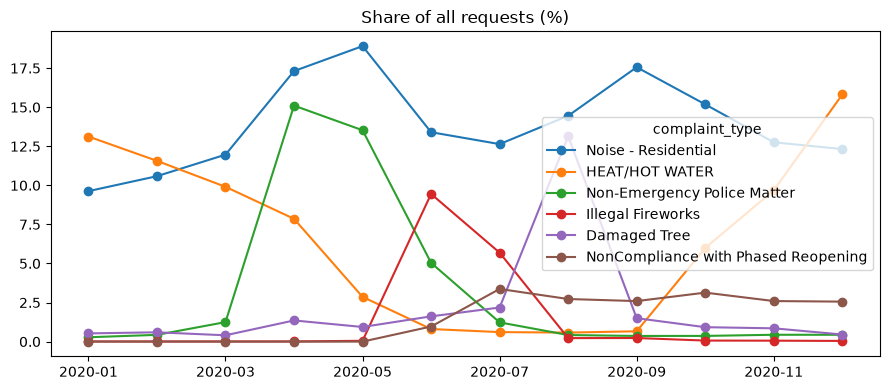

In [9]:
watch = ["Noise - Residential", "HEAT/HOT WATER", "Non-Emergency Police Matter", "Illegal Fireworks",
         "Damaged Tree", "NonCompliance with Phased Reopening"]
shares = pd.crosstab(requests["month"], requests["complaint_type"], normalize="index")[watch] * 100
print(shares.round(1).to_string())
ax = shares.plot(figsize=(9, 4), marker="o", title="Share of all requests (%)")
ax.set_xlabel(""); plt.tight_layout(); plt.show()

**What this tells us.** The mix moves every month. Heat complaints fall in summer and come back in October: that happens every year. "Non-Emergency Police Matter" grows about tenfold in April, when people reported crowds during the lockdown. Illegal fireworks fill June. On 4 August, Tropical Storm Isaias brought down trees, and "Damaged Tree" becomes 13.1% of August.

Some complaint types did not exist before. Run the cell to list the new types with at least 20 requests in the sample.

In [10]:
before = set(requests.loc[requests["month"] <= "2020-02", "complaint_type"])
new = requests[~requests["complaint_type"].isin(before)]
print(new.groupby("complaint_type")["created"].agg(first="min", requests="size")
      .query("requests >= 20").sort_values("first").to_string())

                                                  first  requests
complaint_type                                                   
COVID-19 Non-essential Construction 2020-04-02 08:42:57       321
Illegal Animal Kept as Pet          2020-04-06 15:59:55        27
Mosquitoes                          2020-06-04 13:27:52        20
NonCompliance with Phased Reopening 2020-06-08 10:31:05      2542
Outdoor Dining                      2020-07-01 18:35:50       197
Standing Water                      2020-07-22 00:00:00        37
Real Time Enforcement               2020-09-29 09:08:47        59
Private or Charter School Reopening 2020-10-13 11:04:13        51
Mass Gathering Complaint            2020-10-19 22:03:21       108


The model will meet types it has never seen, such as "NonCompliance with Phased Reopening" from 8 June (2,542 requests in the sample). `make_model()` ignores an unknown type and uses the other inputs, such as the agency.

## 4. Train on January, choose on February

The team trains on **January 2020** and checks on **February 2020**, a month it trusts. February also becomes the **reference** for the drift checks. Four candidates:

- **always "within a week"**: the trivial baseline;
- **lookup by complaint type**: "within a week" if most requests of that type closed within a week in January;
- **logistic regression** on six inputs known on arrival (`make_model()`);
- **boosted trees** on the same inputs (`make_boosted()`).

> **Predict.** The lookup table uses one input, the model six. How many points of accuracy will the model add?

Run the cell. It trains in a few seconds.

In [11]:
train = requests[requests["month"] == "2020-01"]
reference = requests[requests["month"] == "2020-02"]
model = make_model().fit(train[FEATURES], train[TARGET])
boosted = make_boosted().fit(train[FEATURES], train[TARGET])
candidates = {
    "always 'within a week'": np.ones(len(reference), dtype=int),
    "lookup by complaint type": lookup_predict(train, reference),
    "logistic regression": score(model, reference)["prediction"].to_numpy(),
    "boosted trees": (boosted.predict_proba(reference[FEATURES])[:, 1] >= 0.5).astype(int),
}
print(f"February 2020, {len(reference):,} requests: accuracy [95% interval]")
for name, prediction in candidates.items():
    good = int((prediction == reference[TARGET].to_numpy()).sum())
    low, high = wilson(good, len(reference))
    print(f"  {name:26s} {good / len(reference):.1%} [{low:.1%}, {high:.1%}]")

February 2020, 8,558 requests: accuracy [95% interval]
  always 'within a week'     83.2% [82.4%, 84.0%]
  lookup by complaint type   88.4% [87.7%, 89.0%]
  logistic regression        88.9% [88.3%, 89.6%]
  boosted trees              88.8% [88.1%, 89.4%]


> **Check.** You should see 83.2%, 88.4%, 88.9% and 88.8%.

**What this tells us.** The complaint type does almost all the work: the lookup table is only 0.6 points behind, and the intervals overlap. Boosted trees add nothing. The team keeps **logistic regression**: it is as good as the best, small, and it still has an answer for a type that it has never seen. Before the monitoring starts, it writes the **objective**: a month's accuracy should be at least **87%**, February's 88.9% minus 2 points.

## 5. The monitor, month by month

For each month from March to December, the monitor computes four things, as [Data and concept drift](https://learning.nextia-ai.com/courses/mlops/m04/data-and-concept-drift/) taught:

- **input drift**: the PSI of the complaint type, the agency and the channel against February;
- **prediction drift**: the share of requests that the model predicts "within a week" (February: 84.2%);
- **the estimate from the mix**: section 6 explains it;
- **the accuracy**, measured on the complete labels, with its 95% interval. A month is **below objective** when the whole interval is under 87%, and **watch** when only the point is.

> **Predict.** Which month will have the largest input drift? Will it also have the lowest accuracy?

Run the cell.

In [12]:
reference_scored = score(model, reference)
months = [f"2020-{m:02d}" for m in range(3, 13)]
monthly = month_table(model, reference_scored, requests, months)
print(monthly.drop(columns="requests").to_string())

         psi_type  psi_agency  psi_channel  predicted_in_week  estimate_from_mix  accuracy    low   high           status
month                                                                                                                    
2020-03     0.234       0.122        0.009              0.808              0.867     0.878  0.871  0.885  meets objective
2020-04     1.339       0.330        0.138              0.855              0.881     0.894  0.887  0.900  meets objective
2020-05     1.291       0.296        0.208              0.873              0.907     0.911  0.906  0.916  meets objective
2020-06     1.821       0.387        0.210              0.853              0.905     0.895  0.890  0.900  meets objective
2020-07     1.500       0.409        0.136              0.818              0.882     0.869  0.863  0.874            watch
2020-08     1.454       0.651        0.140              0.720              0.830     0.839  0.833  0.844  below objective
2020-09     1.022       

> **Check.** August should show accuracy 83.9% [83.3%, 84.4%] and September 86.1%, both "below objective".

Draw the two signals on one time line. Run the cell.

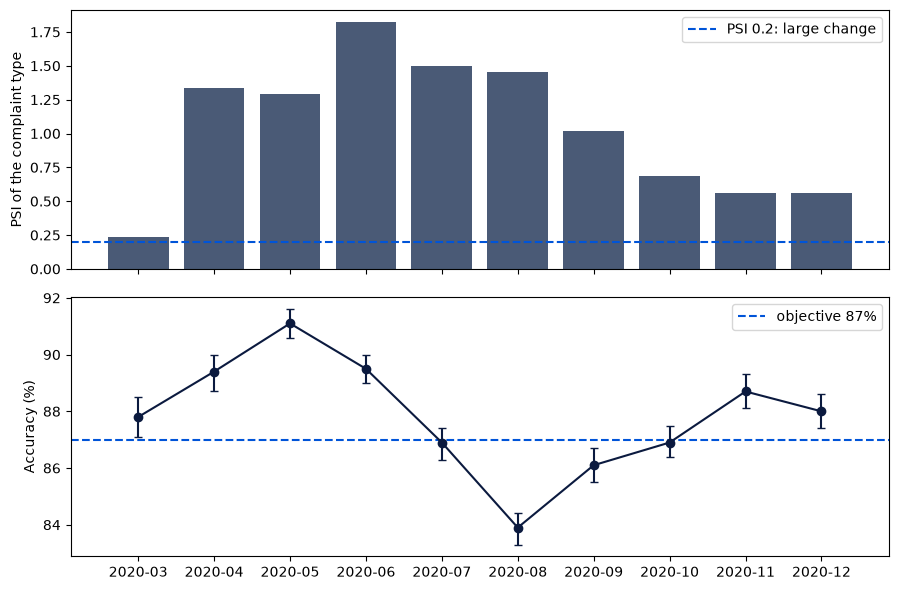

In [13]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
top.bar(monthly.index, monthly["psi_type"], color="#4A5A76")
top.axhline(0.2, color="#0054D8", linestyle="--", label="PSI 0.2: large change")
top.set_ylabel("PSI of the complaint type"); top.legend()
bottom.errorbar(monthly.index, monthly["accuracy"] * 100, yerr=[(monthly["accuracy"] - monthly["low"]) * 100,
                (monthly["high"] - monthly["accuracy"]) * 100], marker="o", color="#0B1A3F", capsize=3)
bottom.axhline(OBJECTIVE * 100, color="#0054D8", linestyle="--", label="objective 87%")
bottom.set_ylabel("Accuracy (%)"); bottom.legend(); plt.tight_layout(); plt.show()

**What this tells us.** The input drift is **large every month**: the complaint type's PSI is above 0.2 from March to December. The largest is June (1.82, fireworks and noise), and June's accuracy is 89.5%, better than February. April and May, with a PSI above 1, are the model's **best** months. Drift alone does not prove that the model is wrong.

The model really was worse in **August** and **September**. Find out why before you decide anything.

> **Your turn.** Compute the PSI of the **agency** input for August against February, with `psi(Counter(...), Counter(...))` on the `agency` column of `reference` and of the August requests. Round it to 3 decimals and name it `psi_agency_august`.

In [14]:
august = requests[requests["month"] == "2020-08"]
psi_agency_august = round(psi(Counter(reference["agency"]), Counter(august["agency"])), 3)
print(psi_agency_august, psi_verdict(psi_agency_august))

0.651 large change


In [15]:
expect_hash("psi_agency_august", psi_agency_august, '4aa931833115df57')

Check passed: psi_agency_august is right.


## 6. What the drift can predict: the estimate from the mix

Drift says that the mix moved. It does not say whether the move hurts. One cheap step helps: take February's accuracy **for each complaint type**, and weight it by this month's mix. That is the accuracy that you would **expect** if only the mix had changed.

A tiny example: in February, the model is right on 95% of noise requests and 60% of tree requests, and the mix is 90% noise, 10% trees: 0.9 × 95% + 0.1 × 60% = 91.5%. If a storm makes the mix 60% noise and 40% trees, the estimate is 0.6 × 95% + 0.4 × 60% = 81%, before any label arrives.

The `estimate_from_mix` column of the table is this number for each month. Compare it with the measured accuracy. Run the cell.

In [16]:
compare = monthly[["estimate_from_mix", "accuracy"]].copy()
compare["gap"] = compare["accuracy"] - compare["estimate_from_mix"]
print(compare.round(3).to_string())

         estimate_from_mix  accuracy    gap
month                                      
2020-03              0.867     0.878  0.011
2020-04              0.881     0.894  0.013
2020-05              0.907     0.911  0.004
2020-06              0.905     0.895 -0.010
2020-07              0.882     0.869 -0.013
2020-08              0.830     0.839  0.009
2020-09              0.889     0.861 -0.028
2020-10              0.890     0.869 -0.021
2020-11              0.888     0.887 -0.001
2020-12              0.891     0.880 -0.011


**What this tells us.** In **August**, the estimate (83.0%) saw the drop coming, at the end of the month, a week before the labels: the mix moved toward types that were already hard. In **September**, the estimate says 88.9%, but the measured accuracy is 86.1%. The mix does not explain that drop: the relationship between a request and its closing time changed. That is **concept drift**, and only labels can see it.

## 7. Where the model really was wrong

Look at the complaint types with the most wrong predictions in August and in September. Run the cell.

In [17]:
def wrong_by_type(month, top=5):
    scored = score(model, requests[requests["month"] == month])
    table = scored.groupby("complaint_type").agg(requests=("right", "size"), wrong=("right", lambda s: int((1 - s).sum())),
                                                 closed_in_week=(TARGET, "mean"), predicted_in_week=("prediction", "mean"))
    table["february_closed_in_week"] = reference.groupby("complaint_type")[TARGET].mean().reindex(table.index)
    return table.sort_values("wrong", ascending=False).head(top).round(2)

for month in ["2020-08", "2020-09"]:
    print(month); print(wrong_by_type(month).to_string()); print()

2020-08


                                     requests  wrong  closed_in_week  predicted_in_week  february_closed_in_week
complaint_type                                                                                                  
Damaged Tree                             2279    772            0.33               0.03                     0.55
Dirty Conditions                          222    178            0.20               1.00                     0.91
NonCompliance with Phased Reopening       473    175            0.63               1.00                      NaN
Request Large Bulky Item Collection      1579    165            0.90               1.00                     0.86
UNSANITARY CONDITION                      349    126            0.36               0.01                     0.29

2020-09
                                     requests  wrong  closed_in_week  predicted_in_week  february_closed_in_week
complaint_type                                                                         

**What this tells us.** In August, the storm brought 2,279 "Damaged Tree" requests, and only 33% of them closed within a week. The model said "not within a week" for almost all of them, which is right two times in three. That is a **hard slice that grew**, as the policy-silent tickets in Module 4. "Dirty Conditions" is different: 91% closed within a week in February, 20% in August. The model still said "within a week". The data does not say why the agency got slower; it only shows that the old relationship stopped holding. In September, "NonCompliance with Phased Reopening", a type the model never saw, closed within a week only 44% of the time.

> **Your turn.** How much of August's drop is the trees? Compute August's accuracy **without** the "Damaged Tree" requests, rounded to 3 decimals, as `august_without_trees`. Use `score(model, ...)` and the `right` column.

In [18]:
august_scored = score(model, requests[requests["month"] == "2020-08"])
august_without_trees = round(august_scored.loc[august_scored["complaint_type"] != "Damaged Tree", "right"].mean(), 3)
print(august_without_trees)

0.865


In [19]:
expect_hash("august_without_trees", august_without_trees, '6270a154bf299d8a')

Check passed: august_without_trees is right.


Without the trees, August is 86.5%: better, and still under 87%. The storm explains part of the drop; the slower agencies explain the rest.

## 8. The failure case: reading the labels too early

At the end of a month, most labels are already known, so it is tempting to measure then. Run the cell: it compares the accuracy on the labels known at the end of each month with the accuracy on all of them.

In [20]:
for month in ["2020-07", "2020-08", "2020-09", "2020-10"]:
    scored = score(model, requests[requests["month"] == month])
    end = pd.Period(month, "M").end_time.ceil("D")  # midnight after the last day
    early, full = accuracy(scored, as_of=end), accuracy(scored)
    print(f"{month}: labels known at month end {early['known'] / early['requests']:.1%}, "
          f"accuracy on them {early['accuracy']:.1%}; on all labels {full['accuracy']:.1%}")

2020-07: labels known at month end 93.7%, accuracy on them 88.3%; on all labels 86.9%
2020-08: labels known at month end 93.7%, accuracy on them 84.8%; on all labels 83.9%
2020-09: labels known at month end 93.4%, accuracy on them 88.0%; on all labels 86.1%


2020-10: labels known at month end 92.9%, accuracy on them 87.7%; on all labels 86.9%


**What this tells us.** At the end of September, 93% of the labels are known, and they say 88.0%: above the objective. All the labels say 86.1%. The labels that arrive first are the requests that closed fast, and the model is right on those more often. **Early labels are not a random sample.** Wait until the labels of every request in the window can be known (here, 7 days after the window ends), or measure only the requests old enough.

## 9. Compare the monitors and the retraining policies

Each monitor raises an alarm in some months. The months that were really bad are those **below objective** on the complete labels: 2020-08, 2020-09. Run the cell.

In [21]:
bad = set(monthly.index[monthly["status"] == "below objective"])
end_of_month = {m: accuracy(score(model, requests[requests["month"] == m]), pd.Period(m, "M").end_time.ceil("D"))["accuracy"]
                for m in months}
alarms = {
    "drift: PSI of the type > 0.2 (month end)": set(monthly.index[monthly["psi_type"] > 0.2]),
    "estimate from the mix < 87% (month end)": set(monthly.index[monthly["estimate_from_mix"] < OBJECTIVE]),
    "early labels < 87% (month end)": {m for m, a in end_of_month.items() if a < OBJECTIVE},
    "complete labels below objective (+7 days)": bad,
}
for name, months_alarmed in alarms.items():
    print(f"{name:44s} alarms {len(months_alarmed):2d}  caught {len(months_alarmed & bad)} of {len(bad)}  "
          f"false {len(months_alarmed - bad)}")

drift: PSI of the type > 0.2 (month end)     alarms 10  caught 2 of 2  false 8
estimate from the mix < 87% (month end)      alarms  2  caught 1 of 2  false 1
early labels < 87% (month end)               alarms  1  caught 1 of 2  false 0
complete labels below objective (+7 days)    alarms  2  caught 2 of 2  false 0


**What this tells us.** The drift alarm catches both bad months, because it fires in **every** month: 8 false alarms. The estimate from the mix catches August and misses September. Early labels miss September too. Only the complete labels are right every time, and they are a week late.

Now the question that Tomás asked in Module 4: "drift alert fired — retrain automatically". Here, the drift alarm fires every month, so that is the same as retraining **every month**. Compare three policies over March to December, with one measure: the share of all requests predicted right. A new model can start on the 8th of a month, when the labels of the month before are complete. Run the cell; it trains a few models and takes a few seconds.

In [22]:
for policy in ["keep", "every_month", "after_label_alarm"]:
    result = simulate_retraining(policy, model, requests, months, bad)
    under = [m for m, a in result["by_month"].items() if a < OBJECTIVE]
    print(f"{policy:18s} accuracy {result['overall']:.1%}  new models {result['releases']:2d}  months under 87%: {under}")

keep               accuracy 87.6%  new models  0  months under 87%: ['2020-07', '2020-08', '2020-09', '2020-10']


every_month        accuracy 88.6%  new models 10  months under 87%: ['2020-08']


after_label_alarm  accuracy 87.6%  new models  2  months under 87%: ['2020-07', '2020-08', '2020-12']


> **Check.** You should see 87.6%, 88.6% and 87.6%.

**What this tells us.** A fresh model every month is 1.0 point better here, with 10 new models; August still stays under the objective. Retraining once on the failing month helps in September and October, and hurts in November and December: a model trained on one odd month learns that month. So a fresher model can help, but the drift alarm is not the reason, and every new model is a release that needs a check before it goes live.

## 10. Change one thing

Suppose the team had written an objective of **86%** instead of 87%.

> **Predict.** Which months are below objective now?

> **Your turn.** Make `flagged_at_86`, the sorted list of months whose whole interval is under 86% (`monthly["high"] < 0.86`).

In [23]:
flagged_at_86 = sorted(monthly.index[monthly["high"] < 0.86])
print(flagged_at_86)

['2020-08']


In [24]:
expect_hash("flagged_at_86", flagged_at_86, '7de7bf43e560608a')

Check passed: flagged_at_86 is right.


With 86%, only 2020-08 is below objective; September (86.1% [85.5%, 86.7%]) becomes "watch". The objective is a decision, made before you look at the data: if you move it after you have seen the numbers, the monitor says what you want to hear.

## 11. The monitor on a new month, end to end

January 2021 is new input. It was not used for anything so far. On **8 February 2021**, every January label can be known. Run the monitor's report as it would read on that day.

In [25]:
january = prepare(load("data/nyc311_2021-01.csv.gz"))
print_report(month_report(model, reference_scored, january, "2021-02-08"), "2021-02-08")

Monthly report, read on 2021-02-08: 11,380 requests
Input drift against the reference month:
         input   psi  p_value        verdict
complaint_type 0.466 3.7e-210   large change
        agency 0.289 1.9e-171   large change
       channel 0.145 7.7e-147   small change
       borough 0.024  9.4e-24 no real change
          hour 0.012  5.9e-05 no real change
Prediction drift: predicted 'within a week' 84.0% (reference 84.2%)
Accuracy expected from the mix (no labels needed): 89.2%
Labels known: 100.0%; accuracy on them: 89.1% [88.5%, 89.7%]
Status: meets objective (objective 87%)


> **Check.** You should see a large change in the complaint type (PSI 0.466), an estimate of 89.2%, accuracy 89.1% [88.5%, 89.7%] and the status "meets objective".

Now run the same report a week earlier, on 1 February. Run the cell.

In [26]:
print_report(month_report(model, reference_scored, january, "2021-02-01"), "2021-02-01")

Monthly report, read on 2021-02-01: 11,380 requests
Input drift against the reference month:
         input   psi  p_value        verdict
complaint_type 0.466 3.7e-210   large change
        agency 0.289 1.9e-171   large change
       channel 0.145 7.7e-147   small change
       borough 0.024  9.4e-24 no real change
          hour 0.012  5.9e-05 no real change
Prediction drift: predicted 'within a week' 84.0% (reference 84.2%)
Accuracy expected from the mix (no labels needed): 89.2%
Labels known: 91.2%; accuracy on them: 90.8% [90.2%, 91.3%]
Status: labels incomplete (objective 87%)


**What this tells us.** On 1 February, 91.2% of the labels are known and they say 90.8%, but the status is "labels incomplete": the monitor refuses to judge early. On 8 February, the model meets its objective, although the drift alarm still says "large change" a year later. The mix of 2021 is a new normal. The team should choose a **new reference month** whose labels it has checked, so that the drift alarm means something again.

## Recap

- Input drift on the complaint type was large in every month of 2020, and the model was below its objective in only two of them.
- The estimate from the mix saw August's drop (a hard slice that grew); only the complete labels saw September's (a relationship that changed).
- The labels that arrive first are optimistic. Judge a month when all its labels can be known.
- A drift alarm opens an investigation. The labels decide; a new model is a release with a check.

Write your monitoring plan on the lesson page, then go on to the next case study.

<img src="https://raw.githubusercontent.com/Nextia-Intelligence/nextia-learning-labs/main/nextia-notebook-branding/assets/section-divider-light.png" alt="" width="100%">

**Next lesson:** [Post-incident review of a public outage](https://learning.nextia-ai.com/courses/mlops/m07/post-incident-review-of-a-public-outage/) · **This lesson:** [read it on the site](https://learning.nextia-ai.com/courses/mlops/m07/monitor-a-model-on-public-data-that-changes/)

<img src="https://raw.githubusercontent.com/Nextia-Intelligence/nextia-learning-labs/main/nextia-notebook-branding/assets/notebook-footer-light.png" alt="Nextia Learning · learning.nextia-ai.com" width="100%">

Free, practical AI courses at [learning.nextia-ai.com](https://learning.nextia-ai.com). The data is real public data from NYC Open Data (no restrictions on use); the team and its model are constructed for the course.